# Практическая работа 2

## 0. Выбор датасета

> Подобрать  датасет (**не использовать**: Iris, Titanic, Boston) на ресурсах:

- [UCI Machine Learning Repository](https://archive.ics.uci.edu/)

- [Kaggle](https://www.kaggle.com/)

> Требования к датасету:

- Содержит не менее 1000 записей (чтобы была статистическая значимость).
- Содержит пропуски (NaN) не менее чем в 2 колонках.
- Содержит категориальные признаки (object/category).
- Содержит числовые признаки (int/float).
- Содержит выбросы (можно проверить визуально).

## 1. Загрузка данных

In [71]:
import warnings
warnings.filterwarnings('ignore')
import os
import re
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
import pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline
import seaborn as sns

In [72]:
path = '/content/drive/MyDrive/Универ/Инжиниринг данных/House_Price/house_price_prediction.csv'
df = pd.read_csv(path)
df.head()

,House_ID,Property_Code,Area_Sqft,Bedrooms,Bathrooms,Age_Years,Location,Furnishing_Status,Property_Type,Parking_Spaces,Garden_Available,Distance_To_City_Center_Km,Price
0,1,HP-2018-10000,2548.0,1,1,5.0,Urban,Semi-Furnished,Studio,3,0,3.6,428225.0
1,2,HP-2019-10001,2103.0,2,1,2.0,Suburban,Semi-Furnished,Apartment,1,0,1.3,414559.0
2,3,HP-2020-10002,2653.0,3,2,3.0,Urban,Semi-Furnished,Apartment,2,0,3.0,560716.0
3,4,HP-2021-10003,3266.0,4,3,3.0,Suburban,Semi-Furnished,Villa,1,1,3.2,775550.0
4,5,HP-2022-10004,2036.0,2,1,16.0,Urban,Semi-Furnished,Independent House,1,0,8.3,429372.0


## 2. Первичный (описательный) анализ данных

- Размер датасета
- Информация о данных
- Статистика числовых признаков
- Статистика категориальных признаков
- Количество пропусков по признакам
- Количество уникальных значений по признакам

In [73]:
print('Размер датасета:', df.shape)

print('Информация о данных:')
df.info()

Размер датасета: (7045, 13)
Информация о данных:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7045 entries, 0 to 7044
Data columns (total 13 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   House_ID                    7045 non-null   int64  
 1   Property_Code               7045 non-null   object 
 2   Area_Sqft                   6835 non-null   float64
 3   Bedrooms                    7045 non-null   int64  
 4   Bathrooms                   7045 non-null   int64  
 5   Age_Years                   6835 non-null   float64
 6   Location                    7045 non-null   object 
 7   Furnishing_Status           6835 non-null   object 
 8   Property_Type               7045 non-null   object 
 9   Parking_Spaces              7045 non-null   int64  
 10  Garden_Available            7045 non-null   int64  
 11  Distance_To_City_Center_Km  6833 non-null   float64
 12  Price                       7045 non-null

In [74]:
print('Статистика числовых признаков:')
df.describe().T

Статистика числовых признаков:


,count,mean,std,min,25%,50%,75%,max
House_ID,7045.0,3499.533712,2021.173256,1.0,1751.0,3497.0,5252.0,7.000000e+03
Area_Sqft,6835.0,2227.162717,798.377378,500.0,1732.0,2201.0,2677.0,1.090136e+04
Bedrooms,7045.0,3.353584,1.222321,1.0,2.0,3.0,4.0,6.000000e+00
Bathrooms,7045.0,2.074379,0.905926,1.0,1.0,2.0,3.0,5.000000e+00
Age_Years,6835.0,12.033245,12.217392,0.0,3.0,8.0,16.0,1.080845e+02
Parking_Spaces,7045.0,1.344500,0.851469,0.0,1.0,1.0,2.0,3.000000e+00
Garden_Available,7045.0,0.408517,0.491594,0.0,0.0,0.0,1.0,1.000000e+00
Distance_To_City_Center_Km,6833.0,8.219065,8.804558,0.5,2.3,5.5,11.3,2.159946e+02
Price,7045.0,519221.959739,139497.390240,70717.0,427581.0,512603.0,600299.0,1.768638e+06


In [75]:
print('Статистика категориальных признаков:')
df.describe(include=['object', 'category']).T

Статистика категориальных признаков:


,count,unique,top,freq
Property_Code,7045,7000,HP-2024-16362,2
Location,7045,4,Urban,2436
Furnishing_Status,6835,18,Semi-Furnished,2338
Property_Type,7045,4,Apartment,3182


In [76]:
print("Количество пропусков по признакам:")
mis = df.isnull().sum()
mis_pct = (df.isnull().mean() * 100).round(2)
pd.DataFrame({'Пропуски': mis, "Доля %": mis_pct})

Количество пропусков по признакам:


,Пропуски,Доля %
House_ID,0,0.00
Property_Code,0,0.00
Area_Sqft,210,2.98
Bedrooms,0,0.00
Bathrooms,0,0.00
Age_Years,210,2.98
Location,0,0.00
Furnishing_Status,210,2.98
Property_Type,0,0.00
Parking_Spaces,0,0.00


In [77]:
print('Количество уникальных значений:')
pd.DataFrame({
    'Уникальных': df.nunique(),
    'Тип': df.dtypes.astype(str)
})

Количество уникальных значений:


,Уникальных,Тип
House_ID,7000,int64
Property_Code,7000,object
Area_Sqft,2561,float64
Bedrooms,6,int64
Bathrooms,5,int64
Age_Years,101,float64
Location,4,object
Furnishing_Status,18,object
Property_Type,4,object
Parking_Spaces,4,int64


## 3. Исследовательский анализ данных

- Построить графики распределения (гистограммы, boxplot).

Числовые признаки: ['House_ID', 'Area_Sqft', 'Bedrooms', 'Bathrooms', 'Age_Years', 'Parking_Spaces', 'Garden_Available', 'Distance_To_City_Center_Km', 'Price']
Категориальные признаки: ['Property_Code', 'Location', 'Furnishing_Status', 'Property_Type']


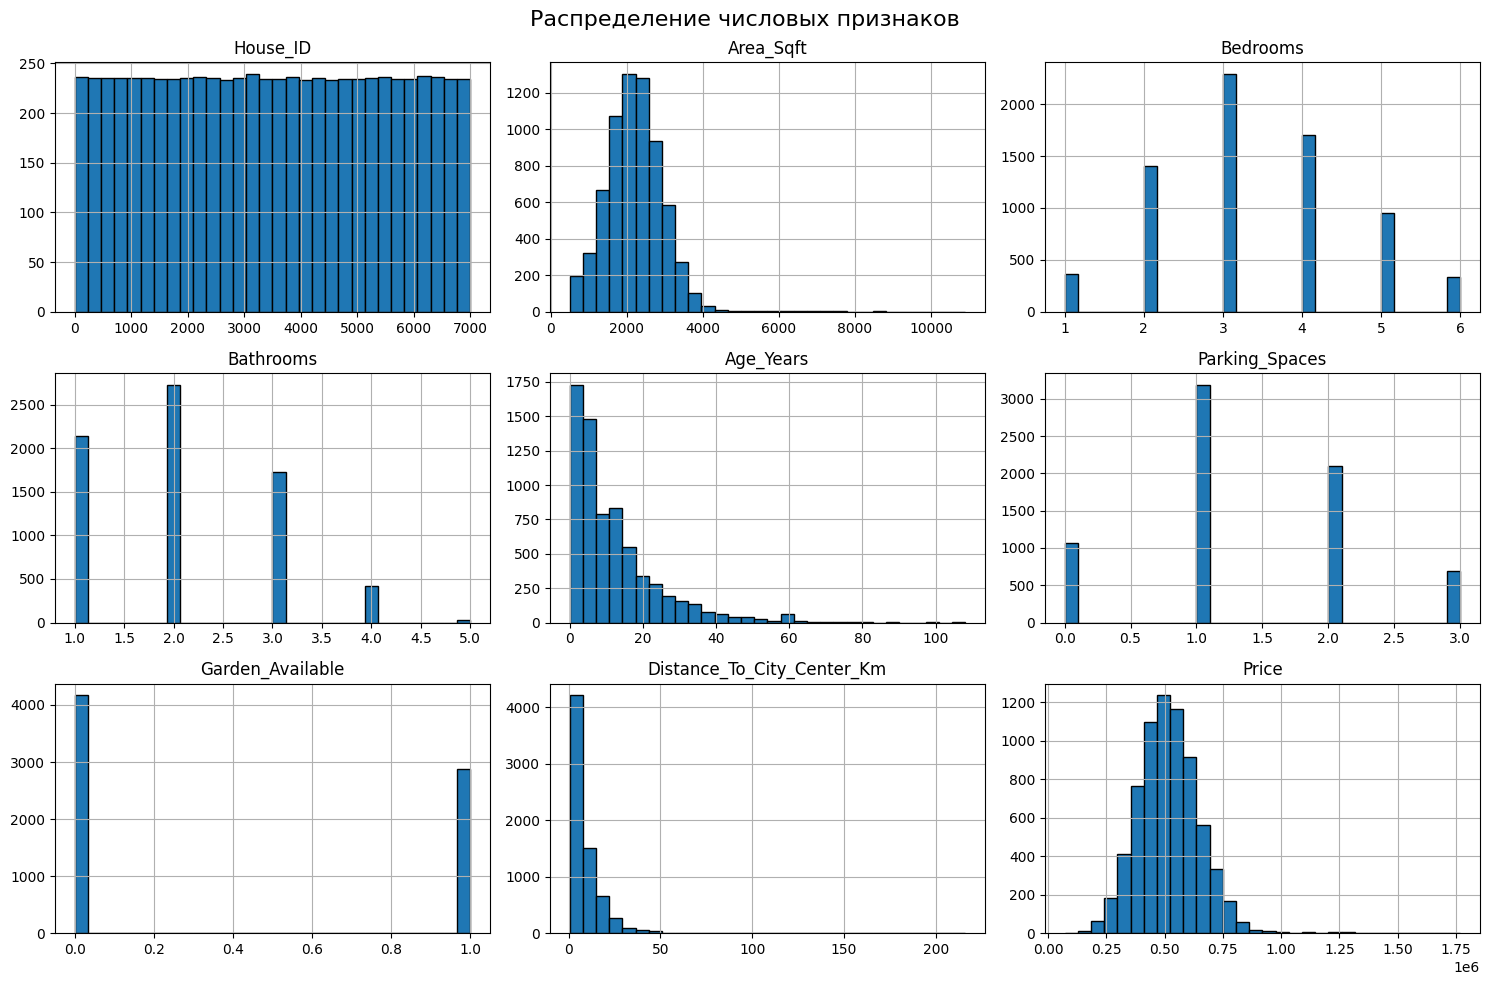

In [78]:
numeric_features = df.select_dtypes(include=[np.number]).columns.tolist()
categorical_features = df.select_dtypes(include=['object', 'category']).columns.tolist()

print("Числовые признаки:", numeric_features)
print("Категориальные признаки:", categorical_features)
#Гистограммы
df[numeric_features].hist(figsize=(15, 10), bins=30, edgecolor='black')
plt.suptitle("Распределение числовых признаков", fontsize=16)
plt.tight_layout()
plt.show()

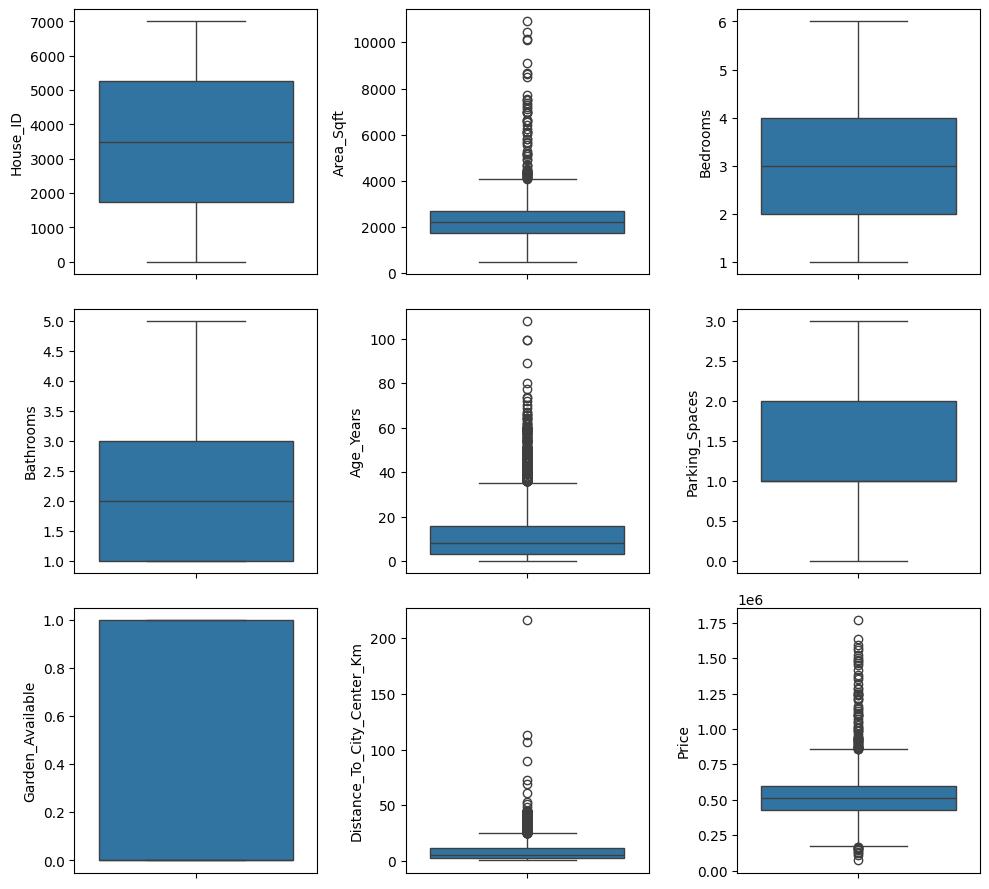

In [79]:
#Boxplot
fig, axes = plt.subplots(nrows=3, ncols=3, figsize=(10, 9))
axes = axes.flatten()
n = len(numeric_features)
for i, col in enumerate(numeric_features):
    sns.boxplot(y=col, data=df, ax=axes[i])
for j in range(n, len(axes)): axes[j].set_visible(False)

plt.tight_layout()
plt.show()

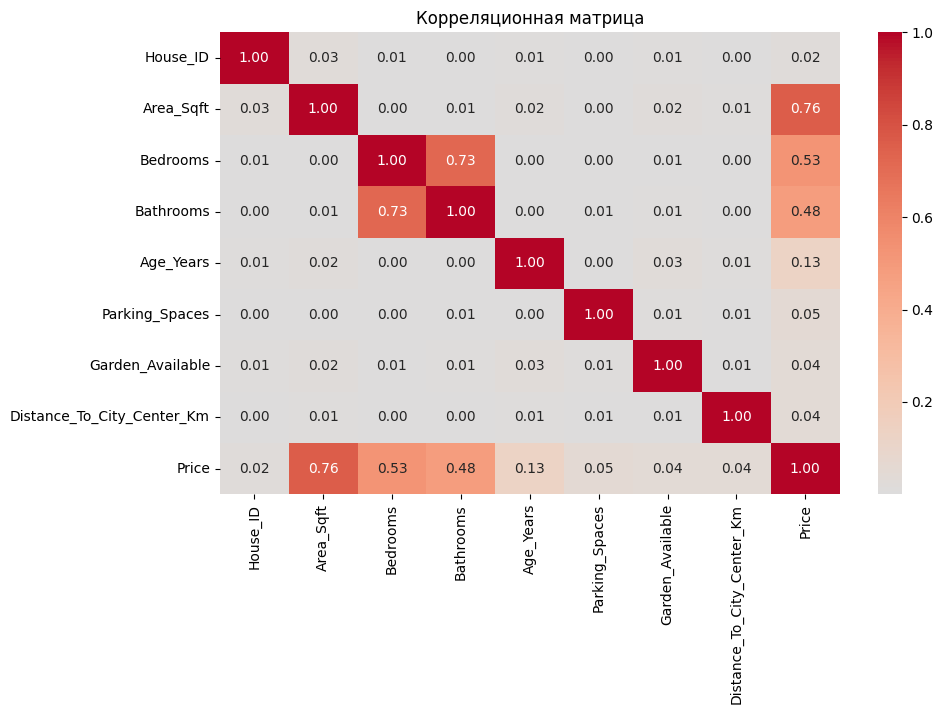

In [80]:
#Тепловая карта
plt.figure(figsize=(10, 6))
sns.heatmap(df[numeric_features].corr().abs(), annot=True, fmt=".2f",
            cmap='coolwarm', center=0)
plt.title("Корреляционная матрица")
plt.show()

## 4. Предобработка данных

В рамках предобработки необходимо выполнить:

- Обработка NaN значений.
- Обработка категориальных признаков.
- Удаление дубликатов.
- Обработка выбросов.
- Масштабирование (нормализация / стандартизация).

> Операции обработки NaN значений, категориальных признаков, масштабирование реализовать через пайплан.

Вместо использования отдельных операций по предобработке данных в Jupyter, необходимо построить пайплайн с  `Pipeline` и `ColumnTransformer`.
> **Требование**: Использовать ColumnTransformer для применения разных трансформаций к разным типам колонок.

Перед реализацией пайплана разделить признаки по типам (обязательно!) на `numeric_features` и `categorical_features`.

> После применения пайплайна результаты предобработки данных сохранить в файл.

In [81]:
dups = df.duplicated().sum()
print(f"Дубликаты: {dups}")
df = df.drop_duplicates().reset_index(drop=True)
print(f'Размер после удаления: {df.shape}')

target = 'Price' if 'Price' in df.columns else df.columns[-1]
id_like = ['House_ID', 'Property_Code']
X = df.drop(columns=[target] + [c for c in id_like if c in df.columns])
y = df[target]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print('Train:', X_train.shape, "Test:", X_test.shape)

Дубликаты: 44
Размер после удаления: (7001, 13)
Train: (5600, 10) Test: (1401, 10)


In [82]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

numeric_features = X.select_dtypes(include=[np.number]).columns.tolist()
categorical_features = X.select_dtypes(include=['object', 'category']).columns.tolist()

numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='constant', fill_value='missing')),
    ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
])

preprocessor = ColumnTransformer(transformers=[
    ('num', numeric_transformer, numeric_features),
    ('cat', categorical_transformer, categorical_features)
])

pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor)
])

X_train_processed = pipeline.fit_transform(X_train)
X_test_processed = pipeline.transform(X_test)

print('Форма после предобработки:', X_train_processed.shape)

Форма после предобработки: (5600, 34)


In [83]:
feature_names = pipeline.named_steps['preprocessor'].get_feature_names_out()

df_train_processed = pd.DataFrame(X_train_processed, columns=feature_names)
df_test_processed = pd.DataFrame(X_test_processed, columns=feature_names)

save_dir = '/content/drive/MyDrive/Универ/Инжиниринг данных/House_Price/'
df_train_processed.to_csv(f'{save_dir}/train_preprocessed.csv', index=False)
df_test_processed.to_csv(f'{save_dir}/test_preprocessed.csv', index=False)

df_train_processed.head()

,num__Area_Sqft,num__Bedrooms,num__Bathrooms,num__Age_Years,num__Parking_Spaces,num__Garden_Available,num__Distance_To_City_Center_Km,cat__Location_Downtown,cat__Location_Rural,cat__Location_Suburban,...,cat__Furnishing_Status_Un-furnished,cat__Furnishing_Status_Unfurnished,cat__Furnishing_Status_furnished,cat__Furnishing_Status_missing,cat__Furnishing_Status_semi-furnished,cat__Furnishing_Status_unfurnished,cat__Property_Type_Apartment,cat__Property_Type_Independent House,cat__Property_Type_Studio,cat__Property_Type_Villa
0,1.546207,1.346719,1.018082,-0.743788,-0.416329,-0.826252,-0.713439,0.0,0.0,1.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
1,-0.188417,1.346719,2.120839,-0.327735,-0.416329,-0.826252,-0.091522,0.0,0.0,1.0,...,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
2,0.866781,1.346719,1.018082,-0.244524,-0.416329,-0.826252,-0.896355,0.0,1.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
3,-0.023938,-0.286021,-0.084676,1.419687,-0.416329,1.210285,-0.908550,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0
4,1.366545,2.163090,1.018082,-0.826998,-0.416329,-0.826252,0.737700,0.0,0.0,1.0,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0


In [84]:
#Проверка пайплайна моделью
from sklearn.linear_model import LinearRegression

model = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('regressor',    LinearRegression())
])

model.fit(X_train, y_train)
print("R² на тесте:", round(model.score(X_test, y_test), 4))

R² на тесте: 0.9338


## Анализ и обоснование решений

Ответить на вопросы:

### 1. Дубликаты

Сколько найдено? Удалены или оставлены? Почему?

 В датасете найдено 44 полных дубликатов строк. Они удалены, поскольку полные дубликаты строк не несут новой информации, искажают статистические оценки (средние, дисперсии, корреляции).
 При обучении модели приводят к «перекосу» выборки: повторяющиеся записи фактически получают больший вес. В данном датасете колонка House_ID уникальна, а совпадения по всем остальным 12 колонкам одновременно не могут быть реальными рыночными наблюдениями - это артефакт сбора/выгрузки данных.

### 2.  Распределение данных

Анализ графиков распределения (гистограммы, boxplot). Нормальное или нет?

Большинство числовых признаков (в частности price, area, distance_to_city_center_km) имеют правостороннюю (положительную) асимметрию: длинный "хвост" в сторону больших значений. Распределения далеки от нормального:

price и area - по форме имеют ассиметричный график с ярко выраженным пиком в области небольших значений;

дискретные признаки (bedrooms, bathrooms, parking_spaces) далеки от нормального.

Boxplot подтверждает такое распределение: медиана смещена вниз отностительно центра бокса, "усы" сверху длиннее, за ними - множество точек-выбросов. Присутствует заметная асимметрия.

## 3. Масштабирование

Почему выбран StandardScaler или MinMaxScaler?

Выбрали StandardScaler, так как:

Числовые признаки имеют разные единицы измерения и диапазоны (area - сотни/тысячи, bedrooms - единицы). Стандартизация приводит их к сопоставимому масштабу;

StandardScaler устойчивее к выбросам, чем MinMaxScaler: последний "зажимает" значения в [0, 1] по min/max, и единственный экстремальный выброс сожмёт весь остальной диапазон;

Большинство алгоритмов (линейные модели, SVM, KNN, нейросети) предполагают нулевое среднее и единичную дисперсию — это ускоряет сходимость;

MinMaxScaler уместен, когда нужен строго ограниченный диапазон (сигмоидные слои, равномерное распределение).

## 4. Пропуски (NaN)

Сколько пропусков в каждой колонке? Почему выбрана стратегия заполнения (median, mean, constant)?

Пропуски обнаружены в нескольких колонках - фактические значения см. в выводе df.isnull().sum(). В этом датасете типично пропуски встречаются в:

числовых: Area_Sqft (210), Age_Years (210), Distance_To_City_Center_Km (212);

категориальных: Furnishing_Status (210).

Для числовых выбран median. Она устойчива к выбросам и асимметрии: в отличие от mean, она не "уезжает" от длинного верхнего хвоста price/area. Медиана сохраняет центр распределения, даже с экстремумами.

Для категориальных - constant='missing'. Введение отдельной категории missing сохраняет факт пропуска как самостоятельную информацию (иногда пропуск коррелирует с целевой переменной). mode (наиболее частая категория) "размывал" бы реальную структуру данных, искусственно усиливая доминирующий класс.

## 5. Выбросы

Результаты анализа визуализация `boxplot`. Обнаружены ли выбросы? Удалены/заменены/оставлены выбросы? Почему?

По boxplot-графикам обнаружены выраженные выбросы в нескольких числовых признаках: Price, Area, Age и Distance_To_City_Center_Km. Их видно как точки за верхними усами (за пределами Q3 + 1.5·IQR).

Решение: оставить выбросы. Обоснование:

1. В контексте задачи о ценах на недвижимость дорогие объекты - это реальные рыночные наблюдения, а не ошибки измерения. Удаление их исказило бы модель в сторону «среднего» сегмента;

2. Использование StandardScaler (вместо MinMaxScaler) и медианного заполнения NaN делает пайплайн устойчивым к выбросам;

3. При желании их можно было бы заменить (winsorize / clipping по перцентилям 1-99), но это привело бы к потере информации о дорогом сегменте;

4. Полное удаление выбросов существенно сократило бы выборку.

## 6. Кодирование категориальных признаков

Почему выбран OneHotEncoder (а не LabelEncoder или TargetEncoder)?

Потому что:

1. Категориальные признаки (Property_Code, Location, Furnishing_Status, Property_Type) - номинальные, между их значениями нет порядковой связи. LabelEncoder присвоил бы коды 0, 1, 2, и модель «решила» бы, что 2 > 1 > 0, что внесло бы ложную ordinal-структуру;

2. OneHotEncoder создаёт бинарные индикаторы для каждой категории - модель трактует их как независимые состояния;

3. TargetEncoder использует целевую переменную при кодировании, что приводит к утечке данных (data leakage) и переобучению на train-выборке. Его применяют только для высококардинальных признаков, которых здесь нет;

4. В пайплайне OneHotEncoder(handle_unknown='ignore') корректно работает с новыми категориями на тесте — не «падает» и не создаёт NaN.



## 7. ColumnTransformer

Почему такое разделение трансформаций? Как это влияет на масштабируемость?

Разделение на numeric_features и categorical_features обязательно, потому что числовые и категориальные признаки требуют принципиально разных операций:

числовые - заполнение медианой и стандартизация (SimpleImputer + StandardScaler);

категориальные - заполнение константой и one-hot-кодирование (SimpleImputer + OneHotEncoder).

ColumnTransformer позволяет параллельно применить разные цепочки трансформаций к разным подмножествам колонок, не смешивая их и не дублируя код. Это обеспечивает:

Воспроизводимость. Весь препроцессинг инкапсулирован в один объект (можно сохранить через joblib).

Отсутствие утечки данных. fit вызывается только на train - статистики (медианы, средние, категории) не подсматриваются из теста.

Масштабируемость. Легко добавить третью группу признаков (текстовые - TfidfVectorizer, даты - собственный трансформер), просто добавив новый кортеж ('name', transformer, columns) в ColumnTransformer.

Удобство для AutoML/GridSearch. Параметры пайплайна адресуются через preprocessor__num__imputer__strategy и т. п., что позволяет перебирать стратегии заполнения в кросс-валидации.

Читаемость. Сразу видно, какие операции применяются к каким колонкам - это критично для поддержки кода в команде.

Корректность типов. Разные трасформеры ожидают разные типы данных - ColumnTransformer гарантирует, что StandardScaler не получит строки, а OneHotEncoder - непрерывные числа.